### **NAMA : NIRWANA**  
### **NIM : H061241011 (C)**  
### **MATKUL : KECERDASAN ARTIFISIAL**

=== RINGKASAN CURAH HUJAN SINJAI ===
Periode: 2022-01-01 sampai 2022-12-31
Jumlah data valid: 365
Rata-rata hujan: 7.6 mm/hari
Curah hujan maksimum: 64.0 mm/hari
Jumlah hari hujan: 277

=== STATISTIK BULANAN ===
             Rata_Rata_Harian  Maksimum_Harian  Jumlah_Hari_Hujan  Jumlah_Data  Total_Hujan
Bulan_Nomor                                                                                
Januari                 11.16            59.49                 24           31       345.93
Februari                13.77            51.75                 27           28       385.69
Maret                    6.00            30.28                 27           31       186.05
April                    2.76             9.57                 20           30        82.78
Mei                      9.99            64.00                 25           31       309.73
Juni                     6.09            19.56                 25           30       182.82
Juli                     1.67             7.08      

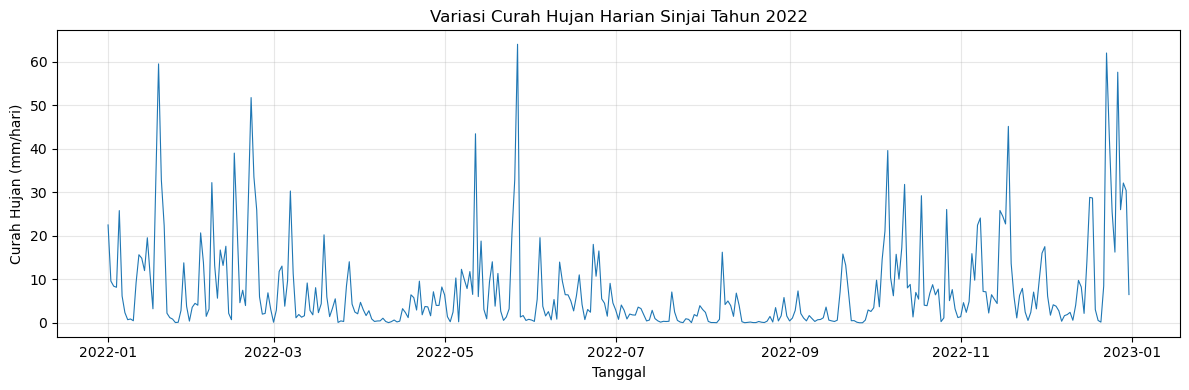

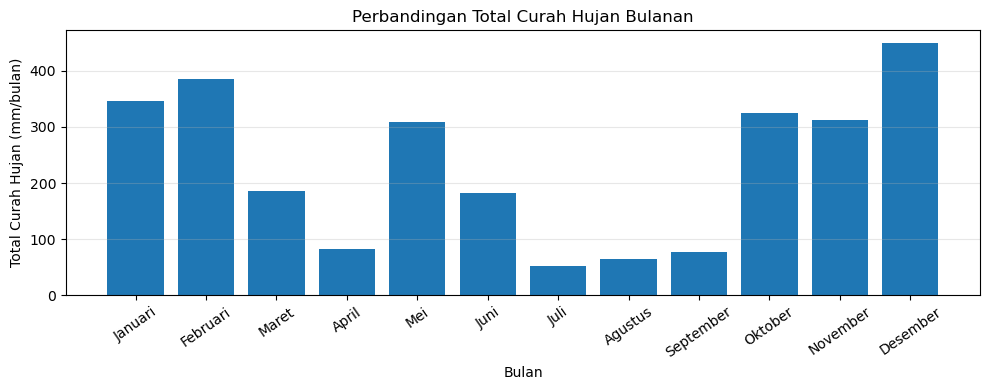

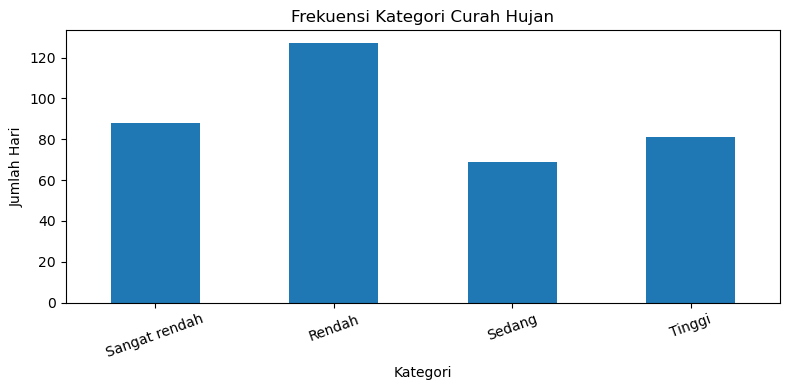


Analisis selesai.
Semua hasil tersimpan di: C:\Users\NIA DAHNIAR\Downloads\hasil_analisis_sinjai


In [10]:

# =====================================================
# RECIPE: ANALISIS KARAKTERISTIK CURAH HUJAN SINJAI
# Sumber data: NASA POWER
# Periode: Januari - Desember 2022
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. MEMBACA DATA
file = Path.home() / "Downloads" / "POWER_Point_Daily_20220101_20221231_005d11S_120d26E_LST.csv"
output = Path.home() / "Downloads" / "hasil_analisis_sinjai"
output.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(file, skiprows=9)

# 2. MEMBERSIHKAN DATA
df["Tanggal"] = pd.to_datetime(
    df["YEAR"].astype(str) +
    df["DOY"].astype(str).str.zfill(3),
    format="%Y%j",
    errors="coerce"
)

df["PRECTOTCORR"] = pd.to_numeric(
    df["PRECTOTCORR"], errors="coerce"
)

df.loc[df["PRECTOTCORR"] < 0, "PRECTOTCORR"] = float("nan")
df = df.dropna(subset=["Tanggal", "PRECTOTCORR"]).copy()
df = df.sort_values("Tanggal")

# 3. MENAMBAHKAN INFORMASI WAKTU
nama_bulan = {
    1: "Januari", 2: "Februari", 3: "Maret",
    4: "April", 5: "Mei", 6: "Juni",
    7: "Juli", 8: "Agustus", 9: "September",
    10: "Oktober", 11: "November", 12: "Desember"
}

df["Bulan_Nomor"] = df["Tanggal"].dt.month
df["Bulan"] = df["Bulan_Nomor"].map(nama_bulan)

# Hari hujan didefinisikan sebagai curah hujan >= 1 mm/hari
df["Hari_Hujan"] = df["PRECTOTCORR"] >= 1

# 4. MENGKLASIFIKASIKAN INTENSITAS HUJAN
def klasifikasi(nilai):
    if nilai < 1:
        return "Sangat rendah"
    elif nilai < 5:
        return "Rendah"
    elif nilai < 10:
        return "Sedang"
    else:
        return "Tinggi"

df["Kategori_Hujan"] = df["PRECTOTCORR"].apply(klasifikasi)

# 5. STATISTIK RINGKAS
print("=== RINGKASAN CURAH HUJAN SINJAI ===")
print("Periode:", df["Tanggal"].min().date(), "sampai",
      df["Tanggal"].max().date())
print("Jumlah data valid:", len(df))
print("Rata-rata hujan:", round(df["PRECTOTCORR"].mean(), 2), "mm/hari")
print("Curah hujan maksimum:",
      round(df["PRECTOTCORR"].max(), 2), "mm/hari")
print("Jumlah hari hujan:", int(df["Hari_Hujan"].sum()))

# 6. ANALISIS BULANAN
bulanan = df.groupby("Bulan_Nomor").agg(
    Rata_Rata_Harian=("PRECTOTCORR", "mean"),
    Maksimum_Harian=("PRECTOTCORR", "max"),
    Jumlah_Hari_Hujan=("Hari_Hujan", "sum"),
    Jumlah_Data=("PRECTOTCORR", "count")
)

# Total bulanan hanya dihitung jika seluruh hari tersedia
total = df.groupby("Bulan_Nomor")["PRECTOTCORR"].sum()
hari_tersedia = df.groupby("Bulan_Nomor")["Tanggal"].count()

hari_seharusnya = pd.Series({
    bulan: pd.Period(f"2022-{bulan:02d}").days_in_month
    for bulan in range(1, 13)
})

bulanan["Total_Hujan"] = total.where(
    hari_tersedia == hari_seharusnya
)

bulanan.index = bulanan.index.map(nama_bulan)

print("\n=== STATISTIK BULANAN ===")
print(bulanan.round(2).to_string())

# 7. FREKUENSI KATEGORI HUJAN
frekuensi = df["Kategori_Hujan"].value_counts().reindex(
    ["Sangat rendah", "Rendah", "Sedang", "Tinggi"],
    fill_value=0
)

print("\n=== DISTRIBUSI INTENSITAS HUJAN ===")
print(frekuensi.to_string())

# 8. MENENTUKAN BULAN TERBASAH DAN TERKERING
total_valid = bulanan["Total_Hujan"].dropna()

if not total_valid.empty:
    print("\nBulan terbasah:", total_valid.idxmax())
    print("Total hujan:", round(total_valid.max(), 2), "mm")

    print("Bulan terkering:", total_valid.idxmin())
    print("Total hujan:", round(total_valid.min(), 2), "mm")

# 9. GRAFIK CURAH HUJAN HARIAN
plt.figure(figsize=(12, 4))
plt.plot(df["Tanggal"], df["PRECTOTCORR"], linewidth=0.8)
plt.title("Variasi Curah Hujan Harian Sinjai Tahun 2022")
plt.xlabel("Tanggal")
plt.ylabel("Curah Hujan (mm/hari)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(output / "grafik_harian.png", dpi=300)
plt.show()
plt.close()

# 10. GRAFIK STATISTIK BULANAN
plt.figure(figsize=(10, 4))
plt.bar(bulanan.index, bulanan["Total_Hujan"])
plt.title("Perbandingan Total Curah Hujan Bulanan")
plt.xlabel("Bulan")
plt.ylabel("Total Curah Hujan (mm/bulan)")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(output / "grafik_bulanan.png", dpi=300)
plt.show()
plt.close()

# 11. GRAFIK KATEGORI HUJAN
plt.figure(figsize=(8, 4))
frekuensi.plot(kind="bar")
plt.title("Frekuensi Kategori Curah Hujan")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Hari")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(output / "grafik_kategori.png", dpi=300)
plt.show()
plt.close()

# 12. MENYIMPAN HASIL
df.to_csv(output / "data_harian.csv", index=False)
bulanan.to_csv(output / "statistik_bulanan.csv")
frekuensi.to_csv(output / "kategori_hujan.csv", header=["Jumlah_Hari"])

print("\nAnalisis selesai.")
print("Semua hasil tersimpan di:", output)
